# Clustering Analysis — East-West Airlines Customer Segmentation
### K-Means, DBSCAN (and Hierarchical clustering as a cross-check)

---

## 1. Objective
East-West Airlines wants to learn more about its customers: their **flying patterns**, **earning and use of frequent-flyer rewards**, and **use of the airline credit card**. The task is to **identify customer segments via clustering**.

**Plan**
1. Load, inspect and clean the data (missing values, duplicates, outliers, scaling)
2. Exploratory Data Analysis (EDA) with multiple visualisations
3. K-Means — Elbow curve + silhouette analysis to pick *k*
4. DBSCAN — k-distance plot + parameter grid over `eps` and `min_samples`
5. Hierarchical clustering (Ward) — quick cross-check on the objective list
6. Cluster profiling, visualisation (PCA projection), and evaluation with the **silhouette score**
7. Insights and business recommendations

**Data dictionary** (from the `Description` sheet)

| Field | Meaning |
|---|---|
| `ID#` | Unique customer id |
| `Balance` | Miles eligible for award travel |
| `Qual_miles` | Miles counted towards Topflight status |
| `cc1_miles`, `cc2_miles`, `cc3_miles` | Miles earned in last 12 months with Frequent-flyer / Rewards / Small-business credit card, **binned**: 1 = <5k, 2 = 5–10k, 3 = 10–25k, 4 = 25–50k, 5 = >50k |
| `Bonus_miles` / `Bonus_trans` | Miles earned / number of non-flight bonus transactions (12 months) |
| `Flight_miles_12mo` / `Flight_trans_12` | Flight miles / number of flight transactions (12 months) |
| `Days_since_enroll` | Days since the customer enrolled in the programme |
| `Award?` | 1 if the customer has ever redeemed an award, else 0 |

## 2. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import linkage, dendrogram

# Global plotting style and reproducibility
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

## 3. Load the data

In [2]:
# The workbook has two sheets: 'Description' (data dictionary) and 'data' (the customer records)
FILE = "EastWestAirlines.xlsx"
df_raw = pd.read_excel(FILE, sheet_name="data")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


## 4. Data quality checks

In [3]:
# Types, non-null counts, missing values and duplicates
df_raw.info()
print("\nMissing values per column:\n", df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("Duplicate customer IDs:", df_raw["ID#"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB

Missing values per column:
 ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight

In [4]:
# Summary statistics — note the huge gap between the median and max for most mile columns (heavy right skew)
df_raw.drop(columns="ID#").describe().T

,count,mean,std,min,25%,50%,75%,max
Balance,"3,999.00","73,601.33","100,775.66",0.00,"18,527.50","43,097.00","92,404.00","1,704,838.00"
Qual_miles,"3,999.00",144.11,773.66,0.00,0.00,0.00,0.00,"11,148.00"
cc1_miles,"3,999.00",2.06,1.38,1.00,1.00,1.00,3.00,5.00
cc2_miles,"3,999.00",1.01,0.15,1.00,1.00,1.00,1.00,3.00
cc3_miles,"3,999.00",1.01,0.20,1.00,1.00,1.00,1.00,5.00
Bonus_miles,"3,999.00","17,144.85","24,150.97",0.00,"1,250.00","7,171.00","23,800.50","263,685.00"
Bonus_trans,"3,999.00",11.60,9.60,0.00,3.00,12.00,17.00,86.00
Flight_miles_12mo,"3,999.00",460.06,"1,400.21",0.00,0.00,0.00,311.00,"30,817.00"
Flight_trans_12,"3,999.00",1.37,3.79,0.00,0.00,0.00,1.00,53.00
Days_since_enroll,"3,999.00","4,118.56","2,065.13",2.00,"2,330.00","4,096.00","5,790.50","8,296.00"


**Observations**
- There are **no missing values** and **no duplicate rows / IDs**, so no imputation is required.
- `ID#` is only an identifier, so it carries no behavioural information and is **dropped** before clustering.
- Most mile/transaction variables are **extremely right-skewed** (e.g. `Balance` max ≈ 1.7M vs. a median of ~43k). Distance-based algorithms such as K-Means and DBSCAN are very sensitive to this, so outlier handling and scaling are essential.
- `cc1_miles`, `cc2_miles`, `cc3_miles` are **ordinal bins (1–5)**, not raw mile counts. Because the bins are already on a small, comparable scale and are ordered, they are kept as ordinal numbers.

## 5. Pre-processing
### 5.1 Drop the identifier and near-constant columns
- `ID#` is dropped (identifier only).
- `cc2_miles` and `cc3_miles` are **excluded from the clustering features**: over 99% of customers fall in bin 1, so after standardisation the few non-1 values become giant z-scores (up to ≈ 20σ). Such a feature carries almost no information about the bulk of customers, but would let a handful of rows form their own clusters. A first K-Means run with these columns confirmed this — it produced a 13-customer cluster defined only by `cc3_miles`. They are still shown in the EDA.

In [5]:
df = df_raw.drop(columns="ID#").copy()
df = df.rename(columns={"Award?": "Award"})   # '?' in a column name is awkward in code

continuous_cols = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans",
                   "Flight_miles_12mo", "Flight_trans_12", "Days_since_enroll"]
card_cols = ["cc1_miles", "cc2_miles", "cc3_miles"]      # all three credit-card bins (used in EDA)
ordinal_cols = ["cc1_miles"]                              # only cc1 is used for clustering (see below)
binary_cols = ["Award"]
features = continuous_cols + ordinal_cols + binary_cols
print("Features used for clustering:", features)

# cc2_miles / cc3_miles are almost constant: >99% of customers are in bin 1 (<5,000 miles).
for c in ["cc2_miles", "cc3_miles"]:
    print(f"{c}: {(df[c] == 1).mean():.1%} of customers in bin 1")

Features used for clustering: ['Balance', 'Qual_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll', 'cc1_miles', 'Award']
cc2_miles: 98.9% of customers in bin 1
cc3_miles: 99.5% of customers in bin 1


### 5.2 Outlier removal
The continuous features are zero-inflated and heavily skewed, so the classic IQR rule would flag a large share of perfectly normal customers (e.g. every customer who flew at all, since the IQR of `Flight_miles_12mo` is tiny). Instead we remove only **extreme** records using a **|z-score| > 5** rule on the continuous columns. This is conservative: it removes the handful of points that would otherwise dominate the distance calculations (or form one-point clusters) while keeping the genuine long tail of high-value customers.

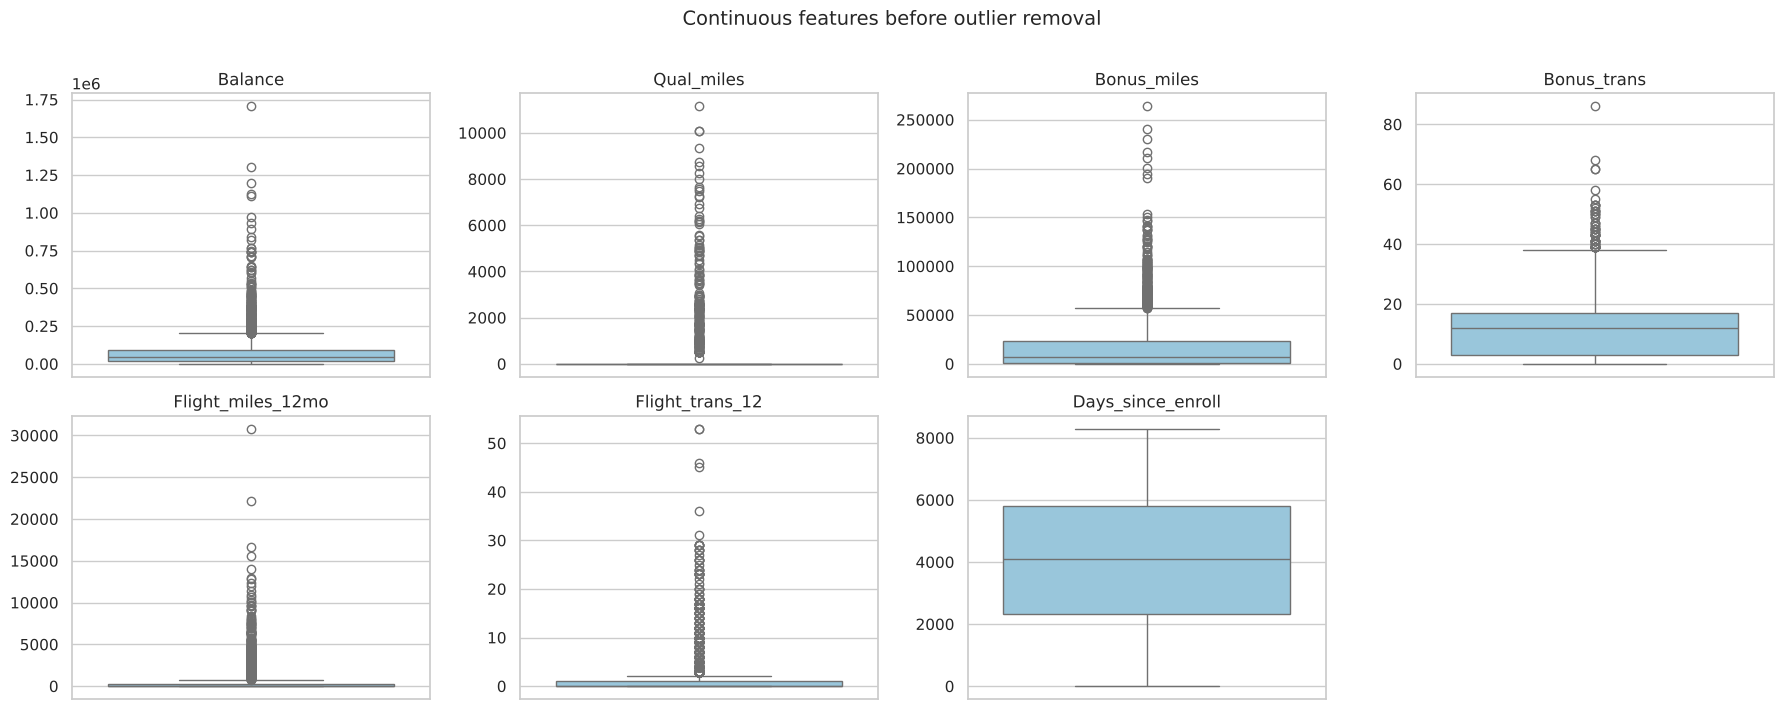

In [6]:
# Boxplots BEFORE outlier removal
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), continuous_cols):
    sns.boxplot(y=df[col], ax=ax, color="#8ecae6")
    ax.set_title(col)
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Continuous features before outlier removal", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [7]:
# z-score outlier detection on the continuous columns
Z_THRESHOLD = 5
z = (df[continuous_cols] - df[continuous_cols].mean()) / df[continuous_cols].std()
outlier_mask = (z.abs() > Z_THRESHOLD).any(axis=1)

print(f"Rows flagged as extreme outliers: {outlier_mask.sum()} ({outlier_mask.mean():.1%} of the data)")
print("\nOutliers flagged per column:")
print((z.abs() > Z_THRESHOLD).sum())

df_clean = df[~outlier_mask].reset_index(drop=True)
print(f"\nShape before: {df.shape}  ->  after: {df_clean.shape}")

Rows flagged as extreme outliers: 125 (3.1% of the data)

Outliers flagged per column:
Balance              26
Qual_miles           42
Bonus_miles          16
Bonus_trans           4
Flight_miles_12mo    30
Flight_trans_12      35
Days_since_enroll     0
dtype: int64

Shape before: (3999, 11)  ->  after: (3874, 11)


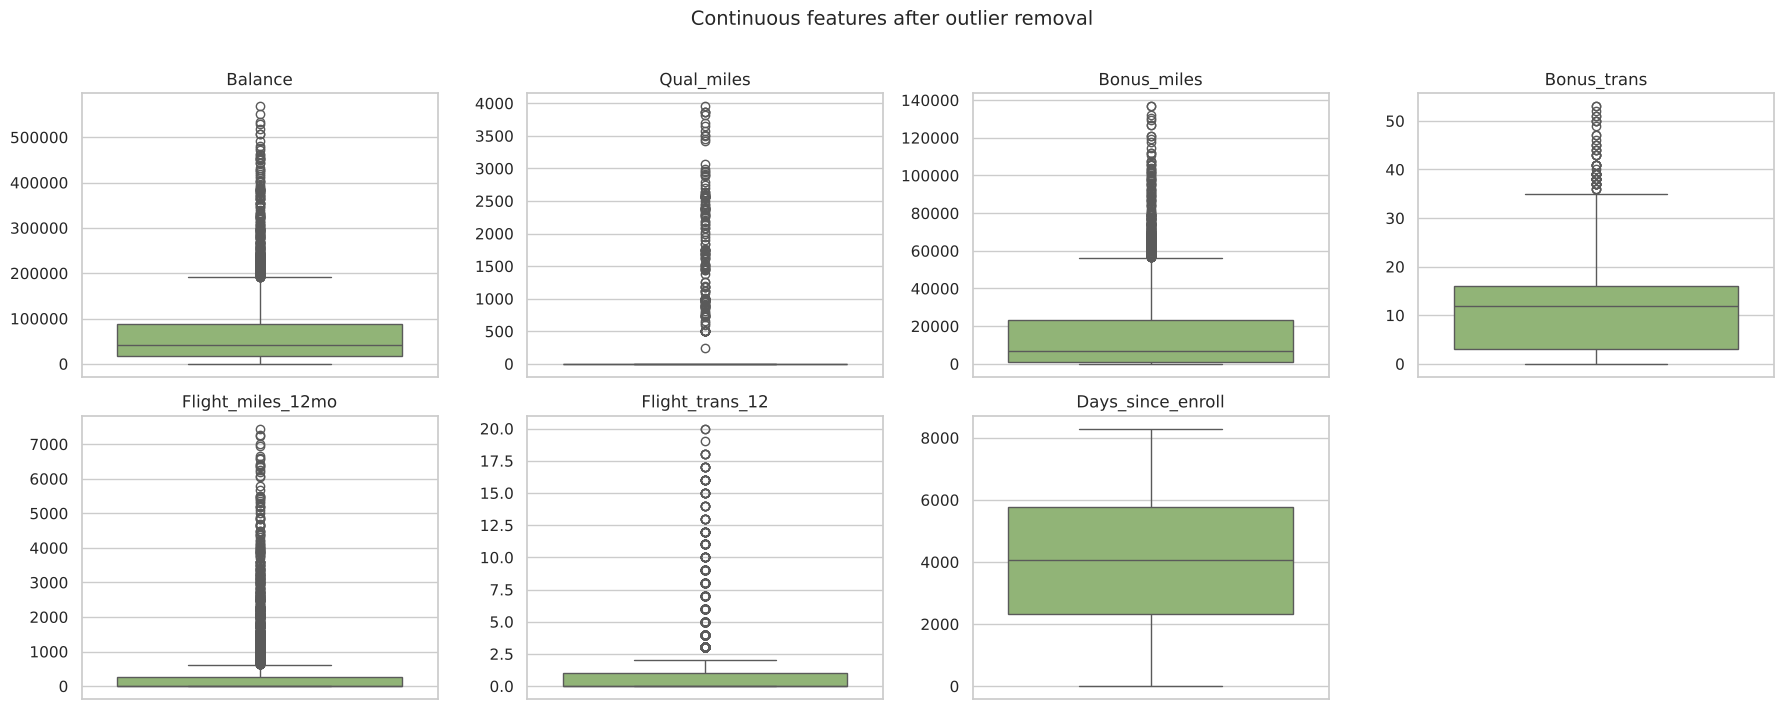

In [8]:
# Boxplots AFTER outlier removal
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), continuous_cols):
    sns.boxplot(y=df_clean[col], ax=ax, color="#90be6d")
    ax.set_title(col)
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Continuous features after outlier removal", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 6. Exploratory Data Analysis (EDA)
EDA is carried out on the **cleaned** data. We look at distributions, categorical structure, relationships between variables and early hints of cluster structure.

### 6.1 Distributions of the continuous features

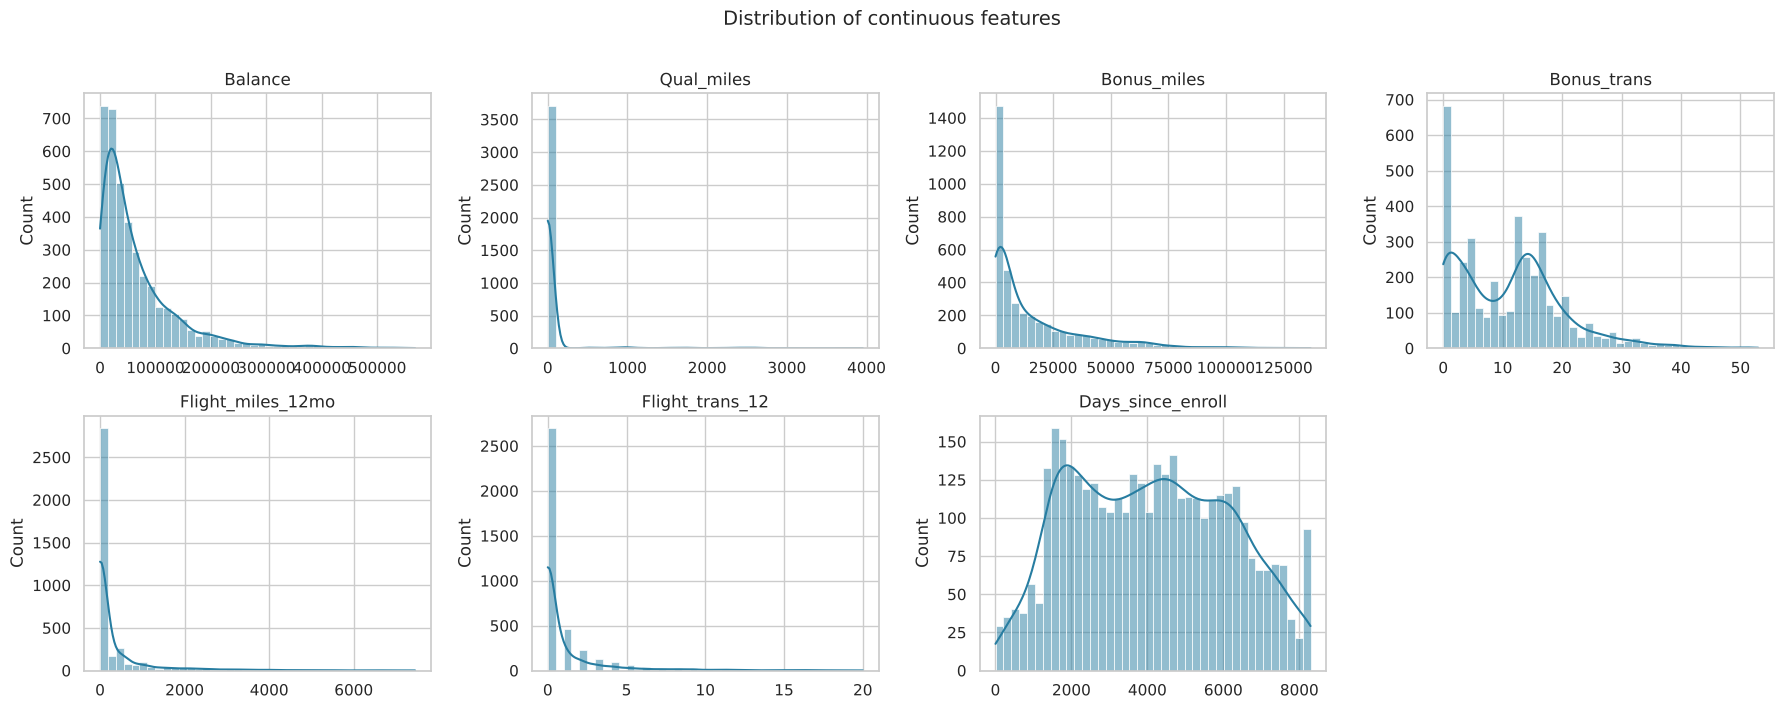

Skewness:
 Balance             2.46
Qual_miles          6.30
Bonus_miles         1.95
Bonus_trans         0.88
Flight_miles_12mo   3.98
Flight_trans_12     3.71
Days_since_enroll   0.12
dtype: float64


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), continuous_cols):
    sns.histplot(df_clean[col], bins=40, kde=True, ax=ax, color="#277da1")
    ax.set_title(col)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Distribution of continuous features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

print("Skewness:\n", df_clean[continuous_cols].skew().round(2))

**Insight:** All mile / transaction variables are strongly right-skewed, with a big spike at zero for `Qual_miles` (96% of customers have none), `Flight_miles_12mo` (70% did not fly at all in the last 12 months) and, to a lesser degree, `Bonus_miles` (12% have none). `Days_since_enroll` is the only well-behaved variable — a fairly even spread with fewer very new and very old members.

### 6.2 Ordinal credit-card bins and the award flag

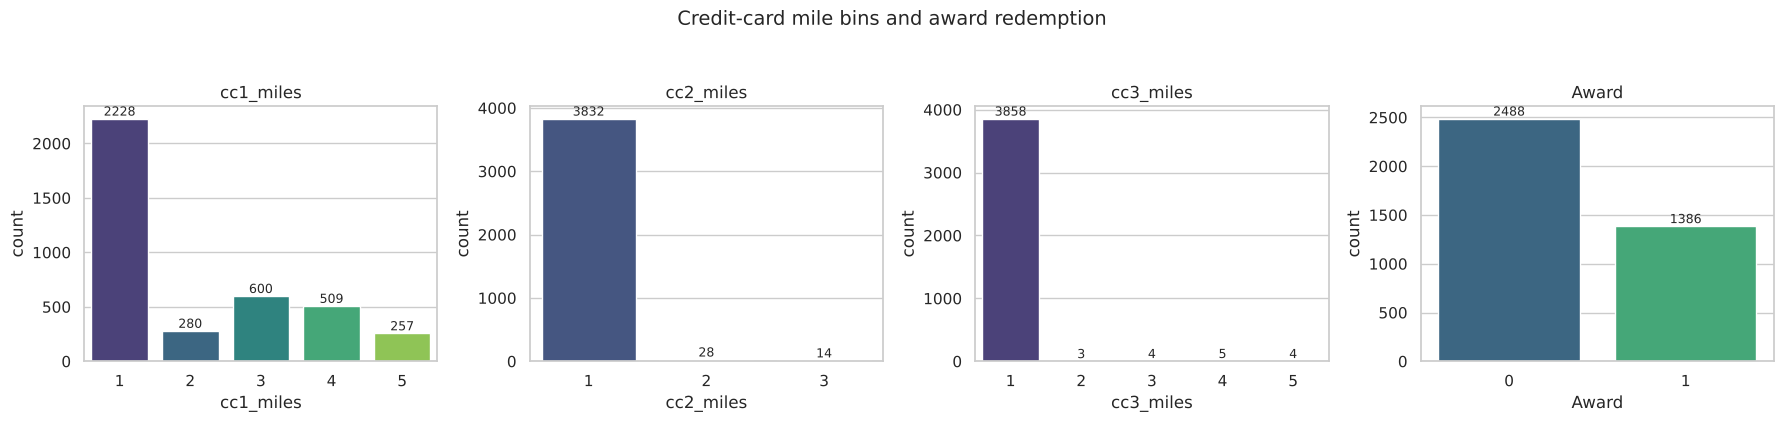

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, card_cols + binary_cols):
    sns.countplot(x=df_clean[col], ax=ax, palette="viridis")
    ax.set_title(col)
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.suptitle("Credit-card mile bins and award redemption", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

**Insight:** `cc2_miles` and `cc3_miles` are almost constant at bin 1 (<5,000 miles) — very few customers use a Rewards or Small-Business card, which is why they are excluded from clustering. The main source of credit-card variation is `cc1_miles` (the frequent-flyer card). About a third of customers have redeemed an award.

### 6.3 Correlation structure

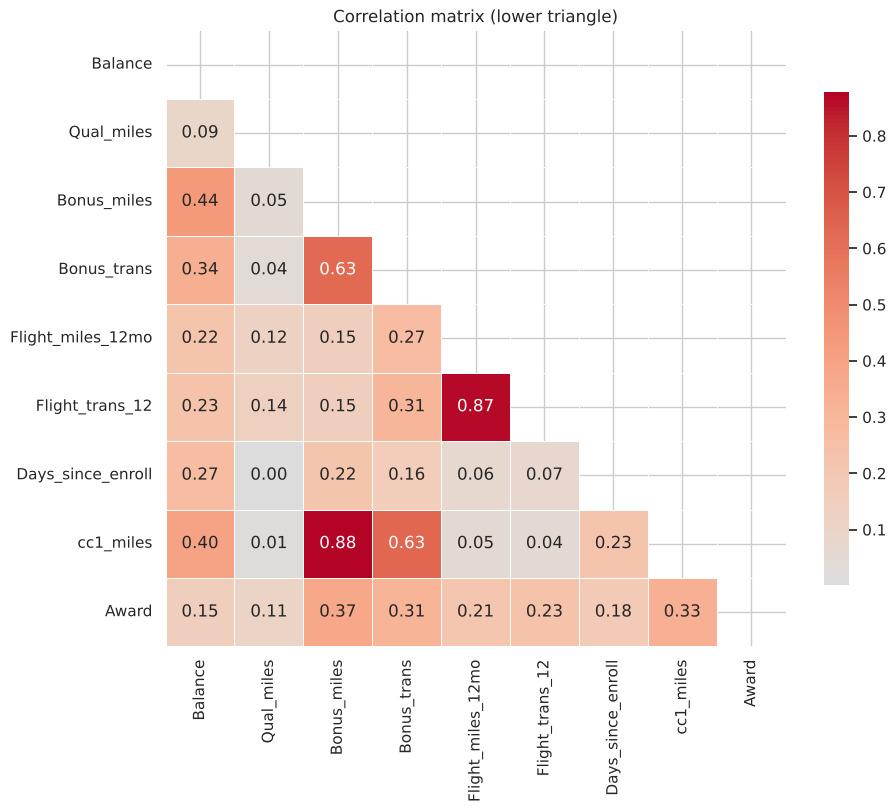

In [11]:
plt.figure(figsize=(10, 8))
corr = df_clean[features].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=np.triu(np.ones_like(corr, dtype=bool)),
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix (lower triangle)")
plt.show()

**Insight:** The strongest relationships are intuitive — `Bonus_miles` ↔ `cc1_miles` (r ≈ 0.88: credit-card spend earns bonus miles), `Flight_miles_12mo` ↔ `Flight_trans_12` (r ≈ 0.87) and `Bonus_miles` ↔ `Bonus_trans` (r ≈ 0.63). Flight activity is almost uncorrelated with card activity (r ≈ 0.05–0.15), so the two behaviours describe *different* customer types. The correlated groups also mean the data has fewer independent dimensions than features, which makes PCA a good tool for 2-D visualisation.

### 6.4 Behavioural patterns: relationships between key variables

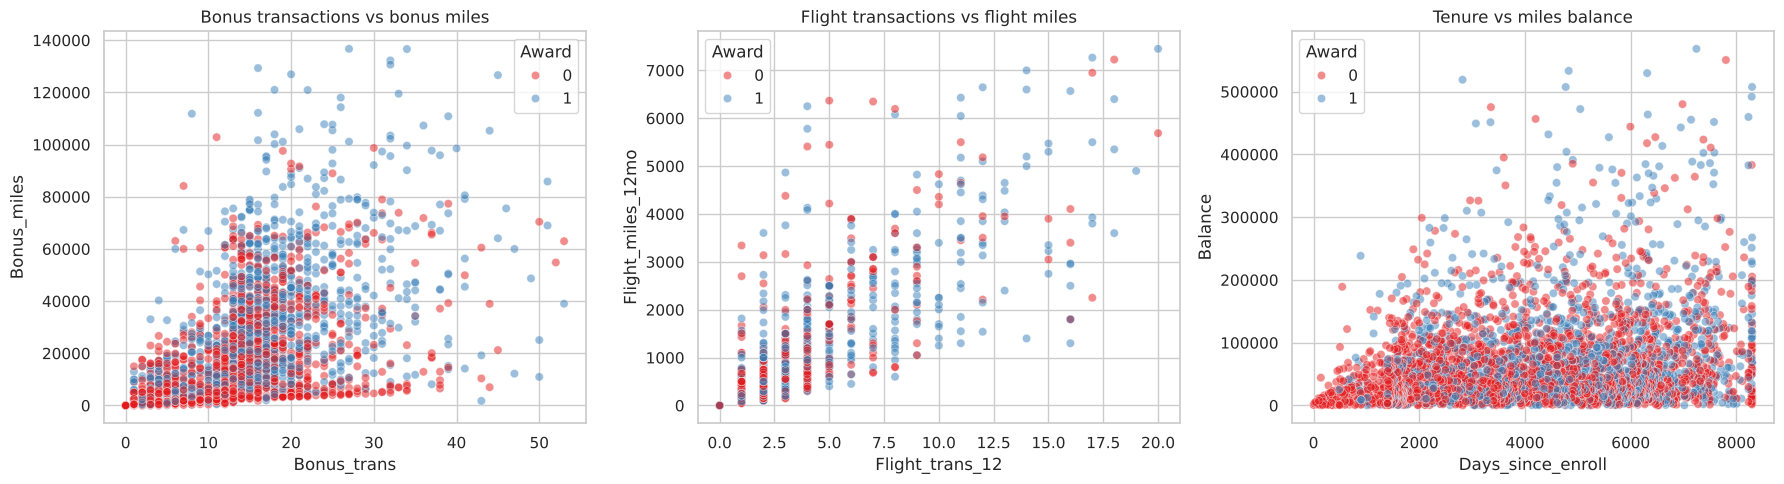

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df_clean, x="Bonus_trans", y="Bonus_miles", hue="Award", palette="Set1", alpha=0.5, ax=axes[0])
axes[0].set_title("Bonus transactions vs bonus miles")

sns.scatterplot(data=df_clean, x="Flight_trans_12", y="Flight_miles_12mo", hue="Award", palette="Set1", alpha=0.5, ax=axes[1])
axes[1].set_title("Flight transactions vs flight miles")

sns.scatterplot(data=df_clean, x="Days_since_enroll", y="Balance", hue="Award", palette="Set1", alpha=0.5, ax=axes[2])
axes[2].set_title("Tenure vs miles balance")
plt.tight_layout()
plt.show()

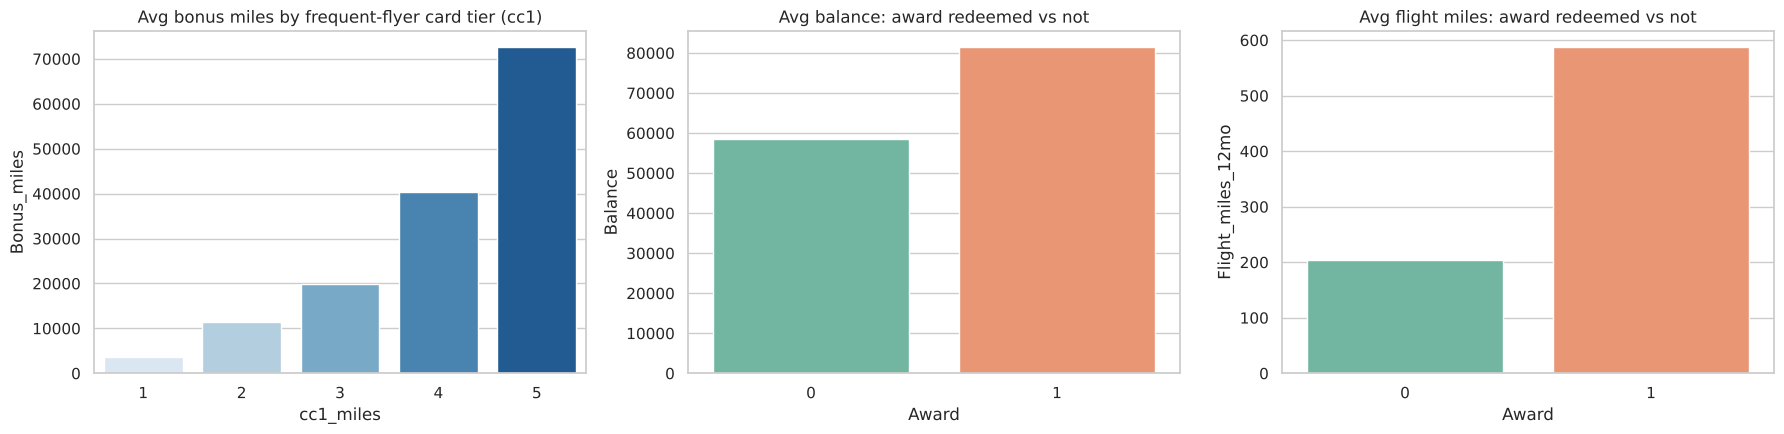

In [13]:
# Mean of key metrics by credit-card tier and award status
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.barplot(data=df_clean, x="cc1_miles", y="Bonus_miles", ax=axes[0], palette="Blues", errorbar=None)
axes[0].set_title("Avg bonus miles by frequent-flyer card tier (cc1)")
sns.barplot(data=df_clean, x="Award", y="Balance", ax=axes[1], palette="Set2", errorbar=None)
axes[1].set_title("Avg balance: award redeemed vs not")
sns.barplot(data=df_clean, x="Award", y="Flight_miles_12mo", ax=axes[2], palette="Set2", errorbar=None)
axes[2].set_title("Avg flight miles: award redeemed vs not")
plt.tight_layout()
plt.show()

**Insights**
- Bonus miles rise steeply with the credit-card tier: customers in the higher `cc1_miles` bins earn far more non-flight miles, so the credit card is the main engine of non-flight earning.
- Flight activity is separate from card activity: most customers sit near zero flights, with a small group of genuine frequent flyers.
- Customers who have redeemed an award have higher balances and more flight activity on average, and a longer tenure.

### 6.5 Transformation and scaling
- **Log transform.** Six features (`Balance`, `Qual_miles`, `Bonus_miles`, `Bonus_trans`, `Flight_miles_12mo`, `Flight_trans_12`) are strongly right-skewed with many zeros. We apply `log1p` (log(1+x), safe for zeros) to compress the long tails so that a few very active customers do not dominate every distance calculation. `Days_since_enroll`, `cc1_miles` and `Award` are left as they are.
- **Standardisation.** K-Means and DBSCAN are **distance-based**; unscaled, `Balance` (tens of thousands) would swamp variables like `Bonus_trans` (single digits) or the 1–5 card bin. `StandardScaler` puts every feature on zero mean / unit variance.

The transformed matrix is used *only* to compute clusters; all cluster **profiles are reported on the original (un-transformed) values** so they stay interpretable.

In [14]:
log_cols = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12"]

df_model = df_clean[features].copy()
df_model[log_cols] = np.log1p(df_model[log_cols])          # reduce skewness

print("Skewness before -> after log1p:")
print(pd.DataFrame({"before": df_clean[log_cols].skew(), "after": df_model[log_cols].skew()}).round(2))

scaler = StandardScaler()
X = scaler.fit_transform(df_model)
print("\nScaled matrix shape:", X.shape)
pd.DataFrame(X, columns=features).describe().T[["mean", "std", "min", "max"]]

Skewness before -> after log1p:
                   before  after
Balance              2.46  -0.94
Qual_miles           6.30   4.63
Bonus_miles          1.95  -1.47
Bonus_trans          0.88  -0.79
Flight_miles_12mo    3.98   0.98
Flight_trans_12      3.71   1.76

Scaled matrix shape: (3874, 9)


,mean,std,min,max
Balance,0.00,1.00,-8.39,2.19
Qual_miles,0.00,1.00,-0.21,5.45
Bonus_miles,-0.00,1.00,-2.38,1.22
Bonus_trans,0.00,1.00,-1.99,1.80
Flight_miles_12mo,0.00,1.00,-0.65,2.29
Flight_trans_12,0.00,1.00,-0.57,3.95
Days_since_enroll,0.00,1.00,-1.99,2.04
cc1_miles,0.00,1.00,-0.77,2.17
Award,-0.00,1.00,-0.75,1.34


### 6.6 2-D view of the data (PCA) — looking for hidden cluster structure
We project the scaled data onto its first two principal components. This projection is used **only for visualisation**; clustering is performed on the full scaled feature space.

Explained variance ratio: [0.377 0.187] | total: 0.564


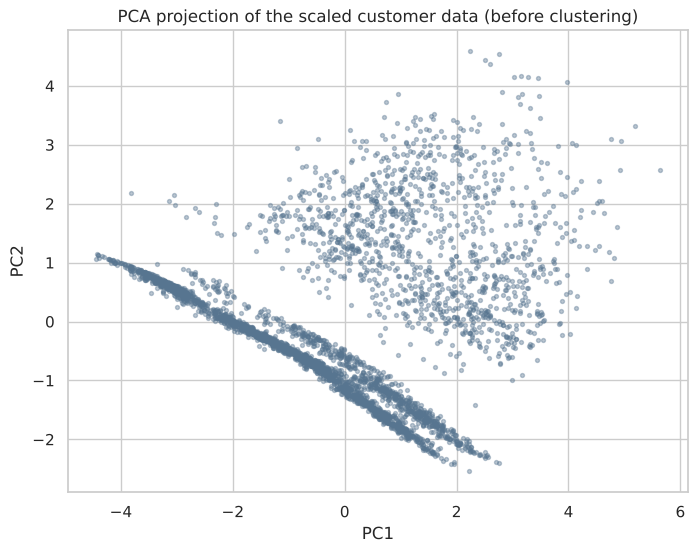

,PC1,PC2
Bonus_miles,0.45,-0.24
Bonus_trans,0.45,-0.23
cc1_miles,0.37,-0.35
Balance,0.35,-0.12
Flight_miles_12mo,0.32,0.58
Flight_trans_12,0.31,0.59
Award,0.29,0.05
Days_since_enroll,0.19,-0.12
Qual_miles,0.10,0.23


In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=8, alpha=0.4, color="#577590")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA projection of the scaled customer data (before clustering)")
plt.show()

# Which original features drive each component?
loadings = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"])
loadings.sort_values("PC1", key=abs, ascending=False)

**Insight:** The cloud is a continuous mass with a dense band and a spread-out upper region rather than perfectly separated blobs, so we should expect moderate (not spectacular) silhouette scores. PC1 (≈ 38 % of variance) is an overall **engagement / card-and-bonus-activity** axis (bonus miles, bonus transactions, `cc1_miles`, balance, award), while PC2 (≈ 19 % of variance) is mainly **flight activity** (`Flight_miles_12mo`, `Flight_trans_12`). Together the two axes explain ≈ 56 %.

## 7. K-Means clustering
### 7.1 Choosing *k* — Elbow curve and silhouette scores
We fit K-Means for k = 2 … 10 and track
- **Inertia (WCSS)** – the elbow marks diminishing returns when adding clusters,
- **Silhouette score** – how well-separated clusters are (−1 to 1, higher is better).

,k,inertia,silhouette
0,2,"26,106.37",0.23
1,3,"20,765.24",0.26
2,4,"17,549.64",0.28
3,5,"15,194.81",0.26
4,6,"13,615.29",0.27
5,7,"12,353.86",0.27
6,8,"11,613.06",0.26
7,9,"10,931.96",0.28
8,10,"10,329.95",0.27


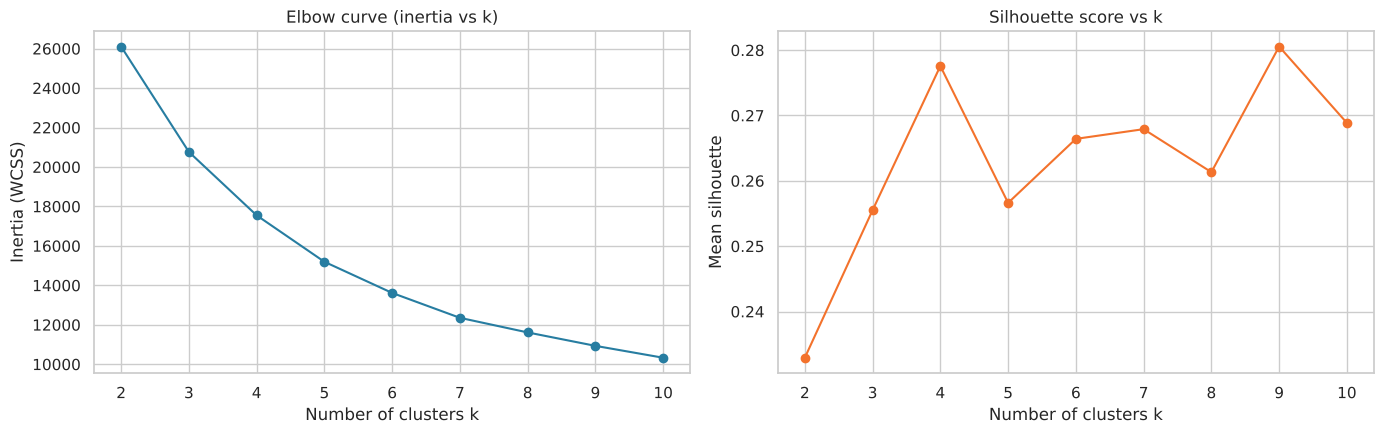

In [16]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

kmeans_results = pd.DataFrame({"k": list(k_range), "inertia": inertias, "silhouette": sil_scores})
display(kmeans_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(kmeans_results["k"], kmeans_results["inertia"], "o-", color="#277da1")
axes[0].set_title("Elbow curve (inertia vs k)")
axes[0].set_xlabel("Number of clusters k"); axes[0].set_ylabel("Inertia (WCSS)")

axes[1].plot(kmeans_results["k"], kmeans_results["silhouette"], "o-", color="#f3722c")
axes[1].set_title("Silhouette score vs k")
axes[1].set_xlabel("Number of clusters k"); axes[1].set_ylabel("Mean silhouette")
for ax in axes:
    ax.set_xticks(list(k_range))
plt.tight_layout()
plt.show()

**Choosing k.** The inertia curve falls smoothly with no sharp elbow (typical for behavioural data without perfectly separated groups), but the largest drops happen up to **k = 4** (26.1k → 20.8k → 17.5k) and the gains shrink afterwards. The silhouette score tells the same story: **k = 4 (≈ 0.278) is the highest of all values k ≤ 8** and is only marginally beaten by k = 9 (≈ 0.281), which would be far too fragmented to act on. We therefore use **k = 4**.

### 7.2 Fit the final K-Means model

In [17]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE)
df_clean["KMeans_cluster"] = kmeans.fit_predict(X)

km_sil = silhouette_score(X, df_clean["KMeans_cluster"])
print(f"K-Means (k={K}) silhouette score: {km_sil:.3f}")
print("\nCluster sizes:")
print(df_clean["KMeans_cluster"].value_counts().sort_index().to_frame("customers").assign(
    share=lambda d: (d["customers"] / len(df_clean)).round(3)))

K-Means (k=4) silhouette score: 0.278

Cluster sizes:
                customers  share
KMeans_cluster                  
0                    1676   0.43
1                    1021   0.26
2                    1016   0.26
3                     161   0.04


### 7.3 Silhouette analysis per cluster

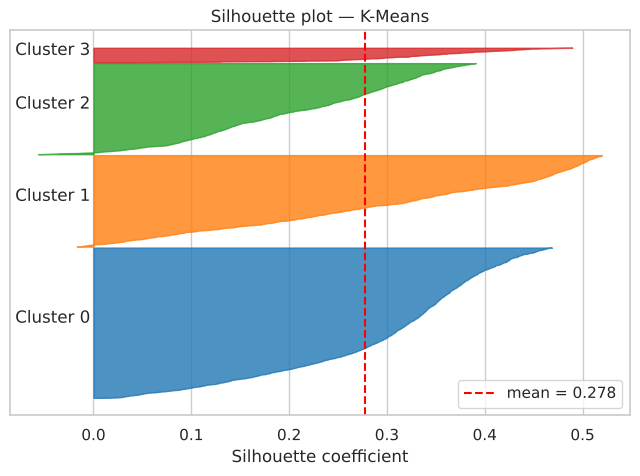

In [18]:
sil_vals = silhouette_samples(X, df_clean["KMeans_cluster"])
fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10
palette = sns.color_palette("tab10", K)
for c in range(K):
    vals = np.sort(sil_vals[df_clean["KMeans_cluster"] == c])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, color=palette[c], alpha=0.8)
    ax.text(-0.08, y_lower + 0.5 * len(vals), f"Cluster {c}")
    y_lower = y_upper + 10
ax.axvline(km_sil, color="red", linestyle="--", label=f"mean = {km_sil:.3f}")
ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([])
ax.set_title("Silhouette plot — K-Means")
ax.legend()
plt.show()

### 7.4 Cluster profiles

,size,Balance,Qual_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,cc1_miles,Award
KMeans_cluster,,,,,,,,,,
0,1676,"72,860.26",0.00,"20,595.12",14.32,0.00,0.00,"4,354.58",2.49,0.38
1,1021,"22,038.82",0.95,863.12,1.77,15.78,0.07,"3,328.99",1.00,0.09
2,1016,"95,368.06",0.00,"23,056.72",15.10,"1,131.55",3.39,"4,423.32",2.34,0.55
3,161,"104,231.83","1,718.47","21,581.74",13.37,970.29,3.12,"4,304.84",2.15,0.65


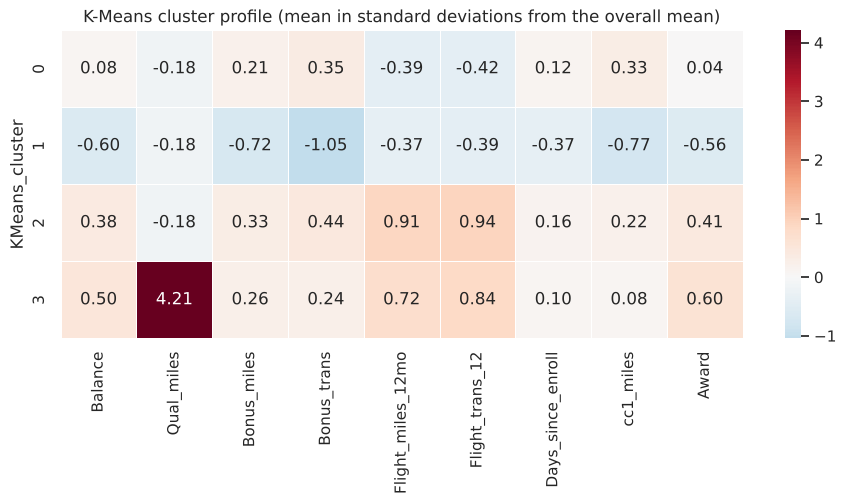

In [19]:
# Mean of every original feature per cluster — this is what we interpret
km_profile = df_clean.groupby("KMeans_cluster")[features].mean()
km_profile.insert(0, "size", df_clean["KMeans_cluster"].value_counts().sort_index())
display(km_profile.round(2))

# Heatmap of z-scored cluster means makes the differences easy to see
km_profile_z = (km_profile[features] - df_clean[features].mean()) / df_clean[features].std()
plt.figure(figsize=(11, 4))
sns.heatmap(km_profile_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("K-Means cluster profile (mean in standard deviations from the overall mean)")
plt.show()

### 7.5 Visualisation of the K-Means clusters

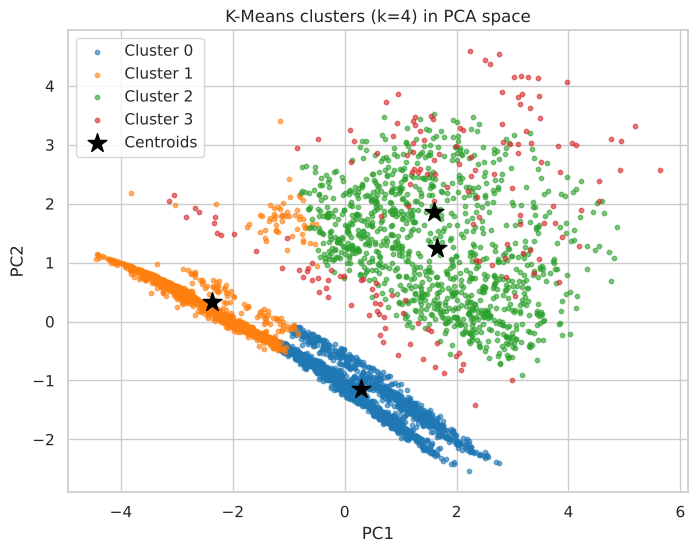

In [20]:
def plot_clusters_pca(labels, title, ax):
    """Scatter of the PCA projection coloured by cluster label (-1 = DBSCAN noise, in grey)."""
    unique = sorted(set(labels))
    colors = sns.color_palette("tab10", max(len(unique), 3))
    for i, lab in enumerate(u for u in unique if u != -1):
        m = labels == lab
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=10, alpha=0.6, color=colors[i], label=f"Cluster {lab}")
    if -1 in unique:
        m = labels == -1
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=10, alpha=0.5, color="grey", marker="x", label="Noise")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title)
    ax.legend(markerscale=2)

fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters_pca(df_clean["KMeans_cluster"].values, f"K-Means clusters (k={K}) in PCA space", ax)
# Plot the centroids in the same PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)
ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c="black", s=200, marker="*", label="Centroids")
ax.legend()
plt.show()

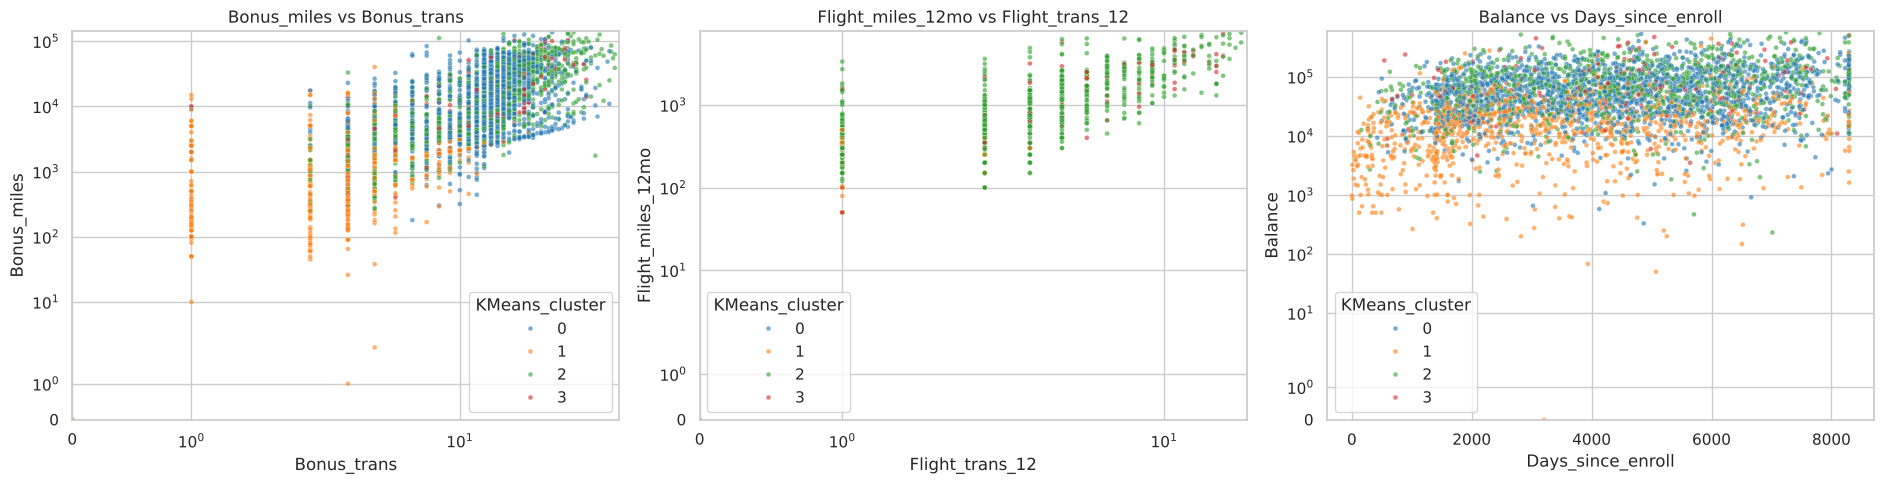

In [21]:
# Additional views in the original (unscaled) feature space
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
pairs = [("Bonus_trans", "Bonus_miles"), ("Flight_trans_12", "Flight_miles_12mo"), ("Days_since_enroll", "Balance")]
for ax, (xcol, ycol) in zip(axes, pairs):
    sns.scatterplot(data=df_clean, x=xcol, y=ycol, hue="KMeans_cluster", palette="tab10", s=12, alpha=0.6, ax=ax)
    ax.set_yscale("symlog"); ax.set_ylim(bottom=0)                       # skewed -> log-like axes (zeros are allowed)
    if xcol != "Days_since_enroll":
        ax.set_xscale("symlog"); ax.set_xlim(left=0)
    ax.set_title(f"{ycol} vs {xcol}")
plt.tight_layout()
plt.show()

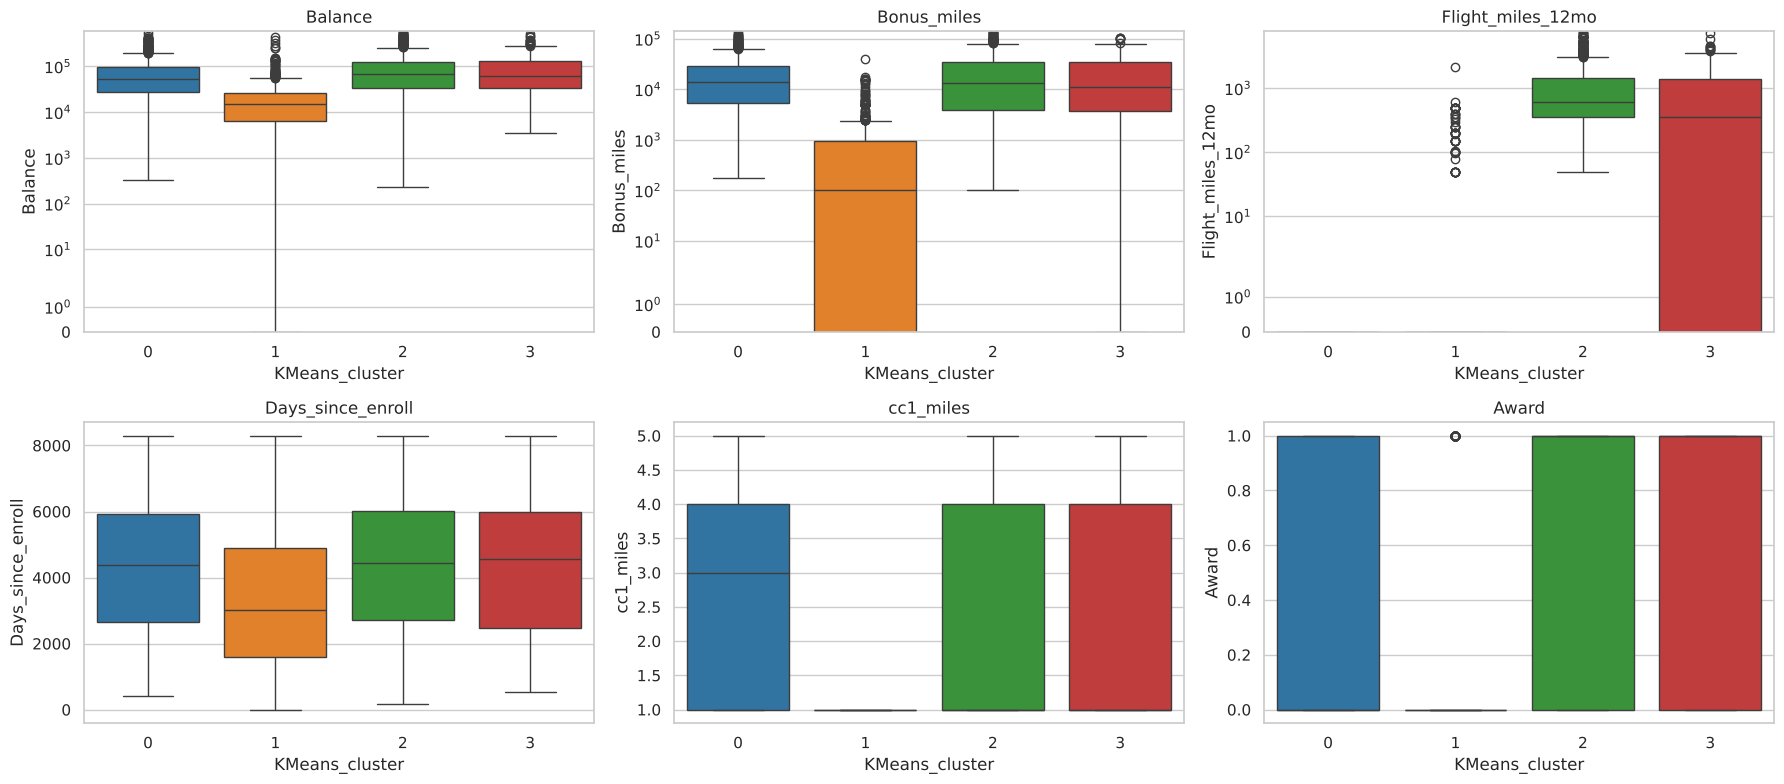

In [22]:
# Distribution of key variables per cluster (skewed variables on a log-like axis)
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.ravel(), ["Balance", "Bonus_miles", "Flight_miles_12mo", "Days_since_enroll", "cc1_miles", "Award"]):
    sns.boxplot(data=df_clean, x="KMeans_cluster", y=col, palette="tab10", ax=ax)
    ax.set_title(col)
    if col in ("Balance", "Bonus_miles", "Flight_miles_12mo"):
        ax.set_yscale("symlog"); ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

### 7.6 Interpretation of the K-Means segments

Silhouette ≈ 0.28 indicates modest but real structure: the groups overlap at their edges (customer behaviour is a continuum), yet they differ clearly on the dimensions that matter for the business. The four segments (profiles are on original values):

| Cluster | Size | Profile | Suggested name |
|---|---|---|---|
| **0** | 1,676 (43 %) | **No flights** in the last 12 months, but healthy card/bonus activity (≈ 20.6k bonus miles, 14 bonus transactions, `cc1` bin ≈ 2.5), large balance (≈ 73k), 38 % have redeemed an award | **Card-driven earners (non-flyers)** |
| **1** | 1,021 (26 %) | Almost no activity of any kind: balance ≈ 22k, ≈ 860 bonus miles, ~2 bonus transactions, practically no flights, all in the lowest card bin, only 9 % redeemed an award, newest members (≈ 3,330 days) | **Low-engagement / dormant** |
| **2** | 1,016 (26 %) | **Active flyers** (≈ 1,130 flight miles, 3.4 flight transactions) that also use the card (≈ 23k bonus miles), highest balance (≈ 95k), 55 % redeemed an award | **Engaged flyers** |
| **3** | 161 (4 %) | The only group with sizeable **qualifying miles** (≈ 1,720 vs ≈ 0 elsewhere), plus ≈ 970 flight miles and the highest balance (≈ 104k) and award rate (65 %) | **Status (Topflight) qualifiers** |

**Insights**
- The most important split is **how customers earn miles**: through the card/bonus partners without flying (cluster 0), through flying (clusters 2 and 3), or hardly at all (cluster 1).
- Cluster 1 (a quarter of the base) is the main **re-activation opportunity**: low balances, recent enrolment, almost no card or flight use.
- Cluster 0 is a large, valuable group that the airline earns from through the card but who *never fly* — a target for offers that convert card miles into trips.
- Cluster 3 is small but distinctive: customers actively chasing Topflight status, ideal for premium-tier retention.

## 8. DBSCAN clustering
DBSCAN groups points that are **density-reachable** and labels sparse points as **noise (-1)**. It needs two parameters:
- `eps` – neighbourhood radius,
- `min_samples` (minPts) – minimum number of neighbours to form a dense region.

### 8.1 k-distance plot to guide `eps`
A common rule of thumb is `min_samples ≈ 2 × n_features`; we use **18** (2 × 9 features) as a starting point. For each point we compute the distance to its 20th nearest neighbour, sort them, and look for the "knee" — the distance where density drops sharply.

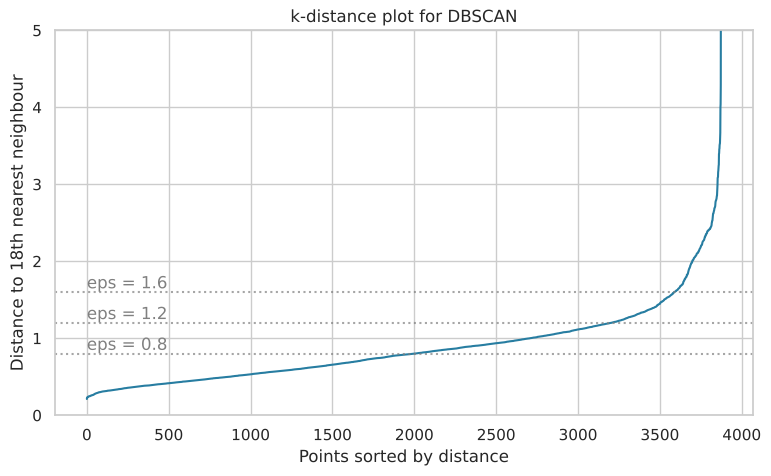

In [23]:
MIN_SAMPLES_START = 2 * len(features)   # rule of thumb: 2 x number of features = 18
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES_START).fit(X)
distances, _ = nn.kneighbors(X)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_dist, color="#277da1")
for e in (0.8, 1.2, 1.6):
    plt.axhline(e, color="grey", linestyle=":", alpha=0.7)
    plt.text(0, e + 0.05, f"eps = {e}", color="grey")
plt.ylim(0, 5)
plt.xlabel("Points sorted by distance"); plt.ylabel(f"Distance to {MIN_SAMPLES_START}th nearest neighbour")
plt.title("k-distance plot for DBSCAN")
plt.show()

The curve is almost flat (≈ 0.3 → 1.2) for roughly 80 % of the points and then bends sharply upward at about **eps ≈ 1.4 – 1.7**; beyond that point are the sparse, isolated customers. Values *below* the knee are strict and leave many points as noise, while values far above it merge everything into one blob. We therefore scan `eps` from 0.6 to 2.0 around the knee.

### 8.2 Parameter experiment (grid over `eps` and `min_samples`)
For each combination we record the number of clusters, the share of points labelled as noise, and the **silhouette score computed on the non-noise points** (silhouette is undefined for noise). Silhouette alone can be gamed by DBSCAN (e.g. one giant cluster plus a few tiny ones, or labelling most points as noise), so a configuration is only considered **valid** if it has
- **at least 3 clusters**, 
- **≤ 15 % noise**, 
- **no cluster larger than 60 %** of the data and **no cluster smaller than 2 %** (≈ 77 customers).

Among valid configurations we choose the highest silhouette.

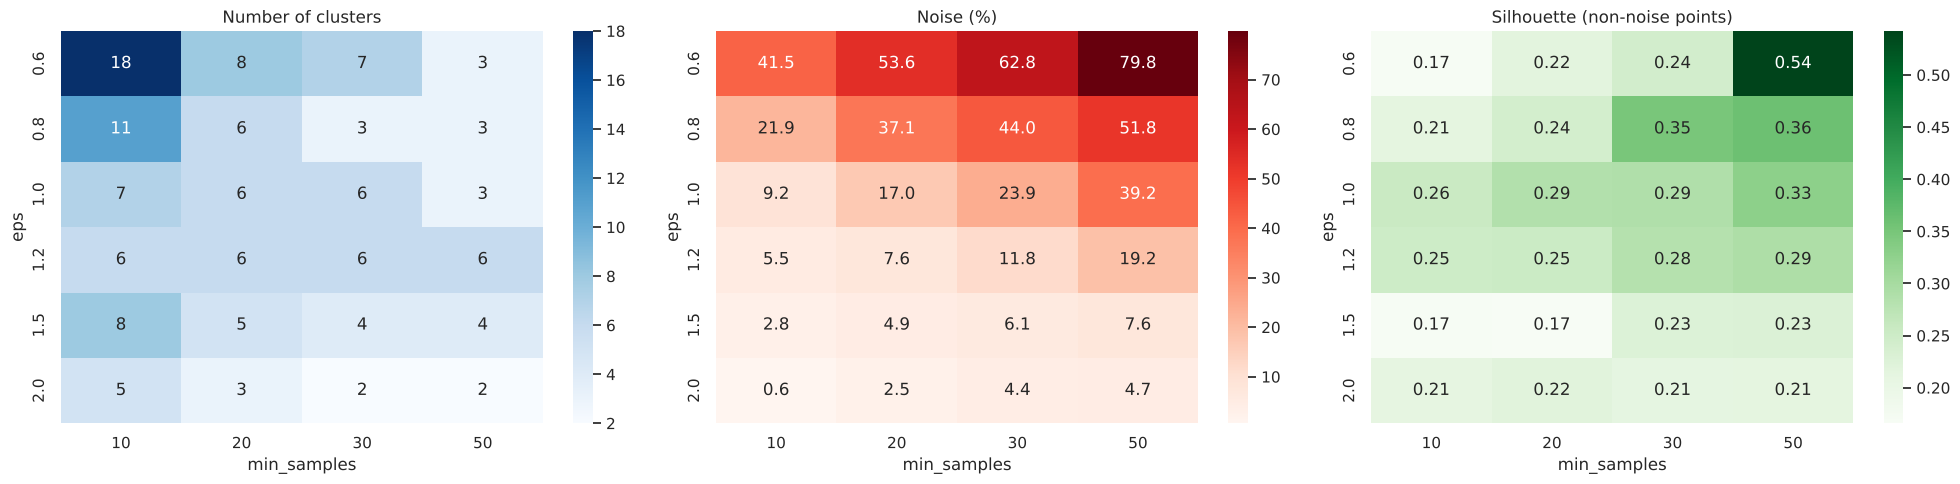

In [24]:
rows = []
for eps in [0.6, 0.8, 1.0, 1.2, 1.5, 2.0]:
    for ms in [10, 20, 30, 50]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        non_noise = labels != -1
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        sil = silhouette_score(X[non_noise], labels[non_noise]) if n_clusters >= 2 else np.nan
        sizes = np.bincount(labels[non_noise]) if non_noise.any() else np.array([0])
        rows.append({"eps": eps, "min_samples": ms, "n_clusters": n_clusters,
                     "noise_pct": 100 * (~non_noise).mean(), "silhouette": sil,
                     "largest_cluster_pct": 100 * sizes.max() / len(X), "smallest_cluster_n": sizes.min()})

dbscan_grid = pd.DataFrame(rows)

# Heatmaps of the grid
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (val, title, fmt, cmap) in zip(axes, [("n_clusters", "Number of clusters", ".0f", "Blues"),
                                               ("noise_pct", "Noise (%)", ".1f", "Reds"),
                                               ("silhouette", "Silhouette (non-noise points)", ".2f", "Greens")]):
    sns.heatmap(dbscan_grid.pivot(index="eps", columns="min_samples", values=val), annot=True, fmt=fmt, cmap=cmap, ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [25]:
# Select the best valid configuration
valid = dbscan_grid[(dbscan_grid["n_clusters"] >= 3) & (dbscan_grid["noise_pct"] <= 15)
                    & (dbscan_grid["largest_cluster_pct"] <= 60) & (dbscan_grid["smallest_cluster_n"] >= 0.02 * len(X))]
display(valid.sort_values("silhouette", ascending=False).head(8).round(3))

best = valid.sort_values("silhouette", ascending=False).iloc[0]
BEST_EPS, BEST_MS = float(best["eps"]), int(best["min_samples"])
print(f"Selected parameters -> eps = {BEST_EPS}, min_samples = {BEST_MS}")

,eps,min_samples,n_clusters,noise_pct,silhouette,largest_cluster_pct,smallest_cluster_n
14,1.20,30,6,11.85,0.28,38.64,130
19,1.50,50,4,7.59,0.23,49.66,483
18,1.50,30,4,6.14,0.23,49.69,494


Selected parameters -> eps = 1.2, min_samples = 30


### 8.3 Fit the final DBSCAN model

In [26]:
dbscan = DBSCAN(eps=BEST_EPS, min_samples=BEST_MS)
df_clean["DBSCAN_cluster"] = dbscan.fit_predict(X)

db_labels = df_clean["DBSCAN_cluster"].values
mask = db_labels != -1
n_db_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
db_sil = silhouette_score(X[mask], db_labels[mask])

print(f"Clusters found: {n_db_clusters}")
print(f"Noise points : {(~mask).sum()} ({(~mask).mean():.1%})")
print(f"DBSCAN silhouette score (excluding noise): {db_sil:.3f}")
print("\nCluster sizes (-1 = noise):")
print(df_clean["DBSCAN_cluster"].value_counts().sort_index().to_frame("customers"))

Clusters found: 6
Noise points : 459 (11.8%)
DBSCAN silhouette score (excluding noise): 0.283

Cluster sizes (-1 = noise):
                customers
DBSCAN_cluster           
-1                    459
 0                   1497
 1                    284
 2                    422
 3                    648
 4                    130
 5                    434


### 8.4 Cluster profiles

,size,Balance,Qual_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,cc1_miles,Award
DBSCAN_cluster,,,,,,,,,,
-1,459,"97,517.21",604.89,"18,851.29",14.06,"1,326.19",4.26,"4,533.73",1.92,0.71
0,1497,"59,253.03",0.00,"12,205.78",10.87,0.00,0.00,"3,865.98",1.87,0.00
1,284,"100,909.37",0.00,"44,024.95",20.62,715.34,2.06,"4,798.72",3.82,1.00
2,422,"24,540.81",0.00,0.00,0.00,0.00,0.00,"3,393.27",1.00,0.00
3,648,"64,009.49",0.00,"25,939.42",14.23,0.00,0.00,"4,570.69",2.82,1.00
4,130,"85,104.43",0.00,"7,183.66",7.46,"1,323.62",3.95,"4,394.06",1.00,1.00
5,434,"76,664.29",0.00,"11,816.72",10.42,778.89,2.21,"3,889.76",1.76,0.00


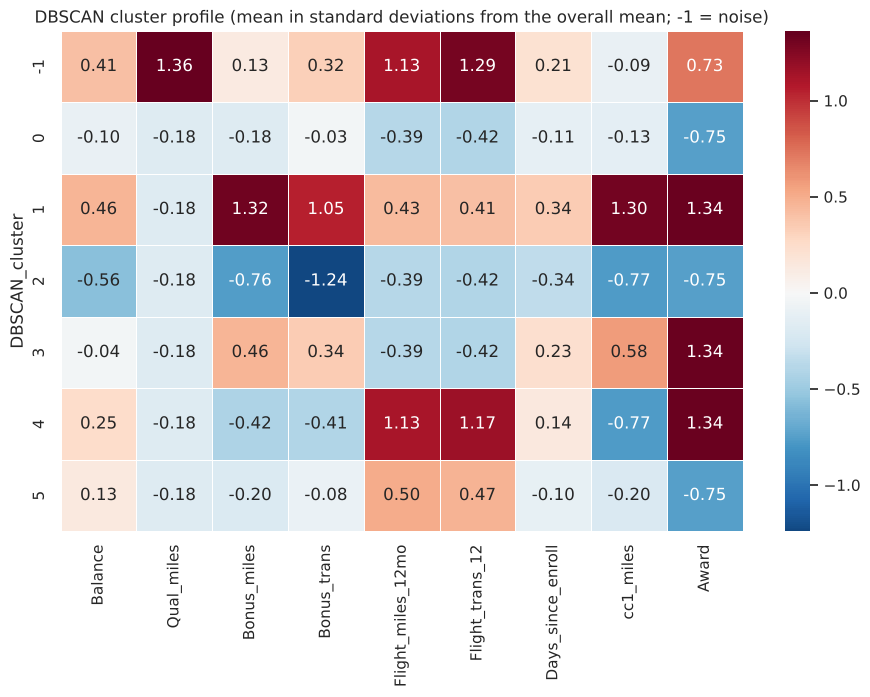

In [27]:
db_profile = df_clean.groupby("DBSCAN_cluster")[features].mean()
db_profile.insert(0, "size", df_clean["DBSCAN_cluster"].value_counts().sort_index())
display(db_profile.round(2))

db_profile_z = (db_profile[features] - df_clean[features].mean()) / df_clean[features].std()
plt.figure(figsize=(11, 3 + 0.5 * len(db_profile)))
sns.heatmap(db_profile_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("DBSCAN cluster profile (mean in standard deviations from the overall mean; -1 = noise)")
plt.show()

### 8.5 Visualisation of the DBSCAN clusters

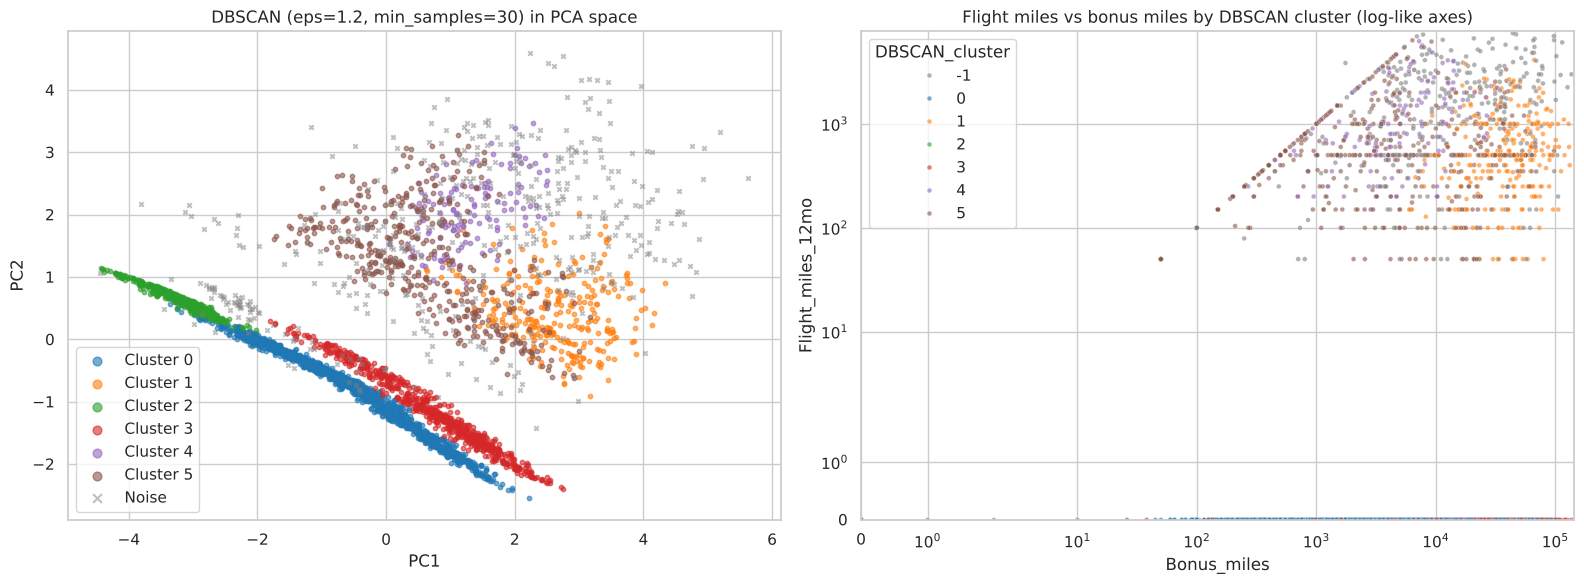

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_clusters_pca(db_labels, f"DBSCAN (eps={BEST_EPS}, min_samples={BEST_MS}) in PCA space", axes[0])

pairs_db = ("Bonus_miles", "Flight_miles_12mo")
# Same colours as the left panel (noise = grey)
db_palette = {lab: ("grey" if lab == -1 else sns.color_palette("tab10")[i]) for i, lab in enumerate(l for l in sorted(set(db_labels)) if l != -1)}
db_palette[-1] = "grey"
sns.scatterplot(data=df_clean, x=pairs_db[0], y=pairs_db[1], hue="DBSCAN_cluster", palette=db_palette, s=12, alpha=0.6, ax=axes[1])
axes[1].set_xscale("symlog"); axes[1].set_yscale("symlog")
axes[1].set_xlim(left=0); axes[1].set_ylim(bottom=0)
axes[1].set_title("Flight miles vs bonus miles by DBSCAN cluster (log-like axes)")
plt.tight_layout()
plt.show()

### 8.6 Interpretation of the DBSCAN result

DBSCAN (`eps = 1.2`, `min_samples = 30`) found **6 dense clusters plus 459 noise points (11.8 %)**, silhouette ≈ 0.28 on the non-noise points. Because `Award` is binary, density regions naturally separate along it, which is why DBSCAN's clusters split more finely on redemption behaviour than K-Means does:

| Cluster | Size | Profile | Suggested name |
|---|---|---|---|
| **0** | 1,497 | No flights, moderate bonus miles (≈ 12k), **never redeemed an award** | Non-flying, no-redemption members |
| **1** | 284 | Highest card use (`cc1` ≈ 3.8, ≈ 44k bonus miles, 21 bonus transactions), some flights, **100 % redeemed** | Premium card power-users |
| **2** | 422 | Zero bonus miles, zero flights, small balance (≈ 25k), newest members | Dormant members |
| **3** | 648 | No flights, strong card use (≈ 26k bonus miles, `cc1` ≈ 2.8), 100 % redeemed | Card-driven redeemers |
| **4** | 130 | Flies (≈ 1,320 miles, 4 flights), **no credit card** (`cc1` = 1), 100 % redeemed | Flight-driven redeemers |
| **5** | 434 | Occasional flyers (≈ 780 miles), moderate bonus miles, not yet redeemed | Occasional flyers, yet to redeem |
| **−1 (noise)** | 459 | Very high flight miles (≈ 1,330), highest balance and the **only** group with notable qualifying miles (≈ 605), 71 % redeemed | Atypical / high-value outliers |

**Insights**
- DBSCAN confirms the same major themes as K-Means (dormant members, card-driven non-flyers, flyers, status chasers) but with **finer separation by award redemption and card tier**.
- Its **noise points are meaningful**: they are the heavy flyers and status qualifiers who do not sit in any dense region — exactly the customers K-Means forced into its clusters.
- DBSCAN is parameter-sensitive: on the raw (un-logged) data, or when judged by silhouette alone, it returned a degenerate answer (one cluster holding ≈ 99 % of customers), which is why we constrained noise and cluster sizes in the selection rule.

## 9. Hierarchical clustering (cross-check)
The assignment objective also mentions hierarchical clustering, so we add a short **Ward-linkage agglomerative** analysis as an independent check on the number of K-Means segments. A dendrogram is built on a random sample of 500 customers (a full 3,800-leaf dendrogram would be unreadable); the model itself is then fitted on all points.

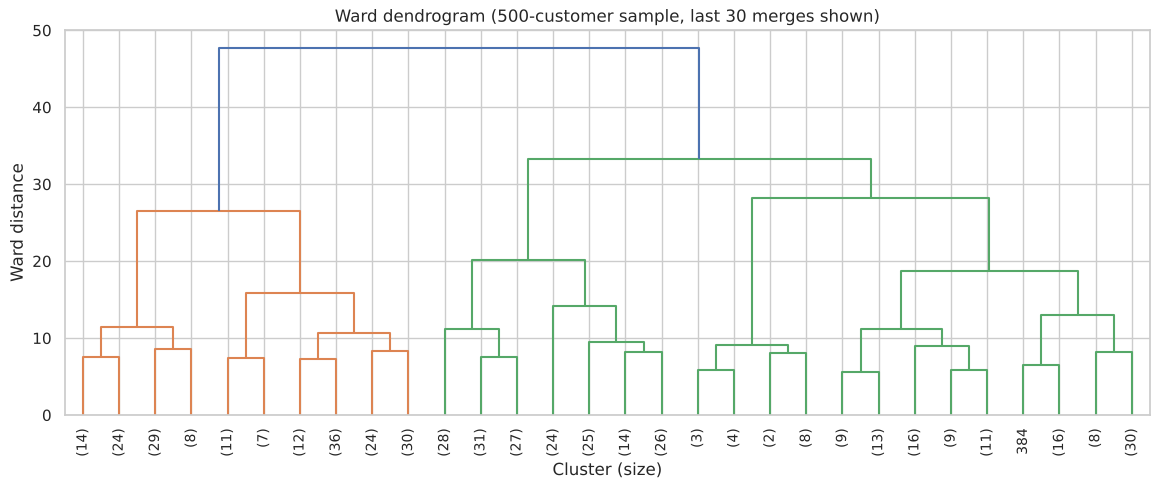

In [29]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X), size=500, replace=False)
Z = linkage(X[sample_idx], method="ward")

plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, color_threshold=0.7 * Z[-1, 2])
plt.title("Ward dendrogram (500-customer sample, last 30 merges shown)")
plt.xlabel("Cluster (size)"); plt.ylabel("Ward distance")
plt.show()

In [30]:
agg = AgglomerativeClustering(n_clusters=K, linkage="ward")
df_clean["Hier_cluster"] = agg.fit_predict(X)
hier_sil = silhouette_score(X, df_clean["Hier_cluster"])
print(f"Hierarchical (Ward, k={K}) silhouette score: {hier_sil:.3f}")

# How similar are the K-Means and hierarchical partitions? (Adjusted Rand Index: 1 = identical)
from sklearn.metrics import adjusted_rand_score
print(f"Adjusted Rand Index vs K-Means: {adjusted_rand_score(df_clean['KMeans_cluster'], df_clean['Hier_cluster']):.3f}")
print("\nCross-tabulation (rows = K-Means, columns = Hierarchical):")
pd.crosstab(df_clean["KMeans_cluster"], df_clean["Hier_cluster"])

Hierarchical (Ward, k=4) silhouette score: 0.248
Adjusted Rand Index vs K-Means: 0.586

Cross-tabulation (rows = K-Means, columns = Hierarchical):


Hier_cluster,0,1,2,3
KMeans_cluster,,,,
0,567,0,1109,0
1,922,53,45,1
2,0,1014,2,0
3,0,0,0,161


**Reading the result.** Ward hierarchical clustering (silhouette ≈ 0.25) reproduces the K-Means structure reasonably well (Adjusted Rand Index ≈ 0.59): the **161-customer status qualifier group is identical** in both methods, and K-Means cluster 2 (engaged flyers) maps almost one-to-one (1,014 of 1,016 customers) onto a single hierarchical cluster. The main disagreement is how the low-activity / card-earner customers (K-Means clusters 0 and 1) are divided — a boundary region where customers form a continuum. The dendrogram shows two large top-level branches that each split into roughly two more groups before the merge heights drop sharply, which is consistent with a small number (≈ 4) of segments and supports the choice of k = 4.

## 10. Evaluation and comparison of the algorithms
Internal evaluation uses the **silhouette score** (higher = more compact and better separated clusters). For DBSCAN the score is computed on the non-noise points only, and the noise share is reported next to it so the comparison is fair.

,Algorithm,Parameters,Clusters,Noise points (%),Silhouette
0,K-Means,k=4,4,0.00,0.28
1,DBSCAN,"eps=1.2, min_samples=30",6,11.85,0.28
2,Hierarchical (Ward),"k=4, linkage=ward",4,0.00,0.25


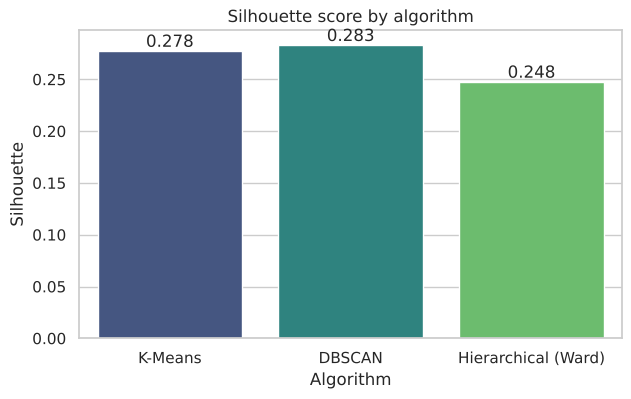

In [31]:
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN", "Hierarchical (Ward)"],
    "Parameters": [f"k={K}", f"eps={BEST_EPS}, min_samples={BEST_MS}", f"k={K}, linkage=ward"],
    "Clusters": [K, n_db_clusters, K],
    "Noise points (%)": [0.0, 100 * (~mask).mean(), 0.0],
    "Silhouette": [km_sil, db_sil, hier_sil],
})
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=comparison, x="Algorithm", y="Silhouette", palette="viridis", ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Silhouette score by algorithm")
plt.show()

| Aspect | K-Means | DBSCAN | Hierarchical (Ward) |
|---|---|---|---|
| Silhouette | ≈ 0.28 | ≈ 0.28 (non-noise points only) | ≈ 0.25 |
| Clusters | 4, sized 43 / 26 / 26 / 4 % | 6 + noise (11.8 %) | 4 |
| Every customer assigned? | Yes | No – 11.8 % labelled noise | Yes |
| Needs *k* up-front? | Yes (elbow + silhouette) | No, but `eps` / `min_samples` are sensitive | Yes (cut the dendrogram) |
| Strength | Simple, balanced, easy to interpret and operationalise | Finds non-spherical groups; isolates atypical customers | Shows nested structure |

**Note on the scores.** All silhouette values are in the 0.25–0.28 range, meaning *modest* cluster separation: customers form a behavioural continuum rather than sharply separated islands. The DBSCAN score is computed after discarding 11.8 % of the data (the hardest points), so it is not strictly comparable to the K-Means score; the three algorithms are effectively **on par**, and K-Means is the more practical choice because it assigns everyone to a balanced, interpretable segment.

## 11. Conclusions and recommendations

**Pre-processing mattered more than the algorithm.** Removing extreme outliers (3.1 %), dropping the near-constant `cc2/cc3` columns, log-transforming the skewed features and scaling were all necessary — without them the algorithms produced 13-customer or "one giant cluster" results.

**Customer segments identified (K-Means, k = 4)**
1. **Card-driven earners (43 %)** – earn miles via the credit card but do not fly → offer ways to convert miles into trips; cross-sell flights.
2. **Low-engagement / dormant (26 %)** – recent, low-balance, nearly inactive → onboarding and re-activation campaigns, first-use bonuses.
3. **Engaged flyers (26 %)** – fly and use the card, high balances → protect with loyalty perks, encourage card upgrades.
4. **Status qualifiers (4 %)** – chasing Topflight status → premium tier retention and personalised offers.

**DBSCAN adds:** a finer split by redemption behaviour and card tier, plus a list of **atypical high-value customers** (noise points) that deserve individual attention.

**Limitations and next steps**
- Silhouette scores are modest (≈ 0.28); segments overlap, so they should be treated as *behavioural tendencies* rather than hard categories.
- The 3 % of extreme customers removed as outliers are probably the very highest-value members and should be handled in a separate VIP programme.
- Further work: test Gaussian Mixture models, include time-based features (recency of last award) if available, and validate segments with campaign A/B tests.